# 05 - Diagnóstico: fatores associados à nota baixa

Pergunta: quais fatores de entrega se associam à nota baixa?

Este é um diagnóstico com variáveis conhecidas apenas após a entrega. Não é um modelo de previsão: para previsão antes da compra, ver o notebook 07.

## 1. Configurações


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix
from sklearn.metrics import precision_score, recall_score
from pathlib import Path

PROCESSED = Path('../data/processed')
FIG = Path('../reports/figures')
TAB = Path('../reports/tabelas')
for p in (FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)

from utils import limpa, COR, JANELA_INICIO as RECORTE_INICIO, JANELA_FIM as RECORTE_FIM, SEED


## 2. Carga de dados

Carrega a base consolidada de pedidos, converte as datas e filtra apenas os pedidos com status de entregues que possuem notas avaliadas.


In [2]:
base = pd.read_csv(PROCESSED / 'base_pedidos.csv', parse_dates=['order_purchase_timestamp'])
base['mes_compra'] = base['order_purchase_timestamp'].dt.to_period('M')

df = base[
    (base['mes_compra'] >= RECORTE_INICIO) & (base['mes_compra'] <= RECORTE_FIM) &
    (base['order_status'] == 'delivered') & (base['review_score'].notna()) &
    (~base['excluir_logistica'])
].copy()
df['nota_baixa'] = (df['review_score'] <= 2).astype(int)

print(f'Pedidos entregues com nota: {len(df):,}')
print(f'Nota média: {df["review_score"].mean():.2f}')
print(f'Notas baixas (1-2): {df["nota_baixa"].sum():,} ({df["nota_baixa"].mean():.1%})')


Pedidos entregues com nota: 94,198
Nota média: 4.15
Notas baixas (1-2): 12,088 (12.8%)


## 3. Preparação das features

Seleciona as variáveis explicativas (features) de caráter logístico e transacional: dias_atraso, qtd_itens, receita_produtos, frete, dias_aprovacao e dias_transporte. Define a variável alvo (y) como a flag de nota baixa.


In [3]:
features = [
    'dias_atraso',
    'qtd_itens',
    'receita_produtos',
    'frete',
    'dias_aprovacao',
    'dias_transporte',
]

antes = len(df)
df = df.dropna(subset=features).copy()
print(f'Removidos {antes - len(df)} pedidos sem data de entrega (features incompletas)')


X = df[features]
y = df['nota_baixa']

print(f'\nFeatures: {features}')
print(f'\nClasse alvo (nota_baixa):')
print(y.value_counts())


Removidos 15 pedidos sem data de entrega (features incompletas)

Features: ['dias_atraso', 'qtd_itens', 'receita_produtos', 'frete', 'dias_aprovacao', 'dias_transporte']

Classe alvo (nota_baixa):
nota_baixa
0    82096
1    12087
Name: count, dtype: int64


## 4. Treino do modelo

Divide os dados em conjuntos de treino (70%) e teste (30%) de forma estratificada e aplica o StandardScaler para normalizar as variáveis numéricas. Em seguida, treina um modelo de Regressão Logística para prever a probabilidade de ocorrência de uma nota baixa.


In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=SEED)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(random_state=SEED, max_iter=1000)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

acc = model.score(X_test_scaled, y_test)
auc = roc_auc_score(y_test, y_pred_proba)

print(f'MODELO TREINADO!')
print(f'Acurácia: {acc:.3f}')
print(f'ROC-AUC: {auc:.3f}')


MODELO TREINADO!
Acurácia: 0.883
ROC-AUC: 0.709


## 5. Avaliação detalhada

Extrai a matriz de confusão e o relatório de classificação para entender o comportamento preditivo do modelo entre as classes "Nota OK" e "Nota Baixa".


In [5]:
print('MATRIZ DE CONFUSAO:')
cm = confusion_matrix(y_test, y_pred)
print(cm)

print('\nRELATORIO DE CLASSIFICACAO:')
print(classification_report(y_test, y_pred, target_names=['Nota OK', 'Nota Baixa']))


MATRIZ DE CONFUSAO:
[[24406   211]
 [ 3105   533]]

RELATORIO DE CLASSIFICACAO:
              precision    recall  f1-score   support

     Nota OK       0.89      0.99      0.94     24617
  Nota Baixa       0.72      0.15      0.24      3638

    accuracy                           0.88     28255
   macro avg       0.80      0.57      0.59     28255
weighted avg       0.87      0.88      0.85     28255



## 6. Importância das features

Extrai e ordena os coeficientes da Regressão Logística para identificar quais fatores mais pesam na insatisfação do cliente.


In [6]:
coef_df = pd.DataFrame({
    'Feature': features,
    'Coeficiente': model.coef_[0]
}).sort_values('Coeficiente', ascending=False)

print('COEFICIENTES PADRONIZADOS (regressão logística)')
print(coef_df.to_string(index=False))

print('\n' + '=' * 70)
print('LEITURA')
print('=' * 70)
print('Coeficiente positivo: maior nota baixa associada ao fator, mantidos os demais constantes.')
print('Coeficiente negativo: menor nota baixa associada ao fator, mantidos os demais constantes.')
print('Os valores são padronizados, então podem ser comparados em magnitude entre si.')
print('Associação, não causa. Atraso e transporte estão correlacionados entre si,')
print('por isso os coeficientes individuais são instáveis; ver a análise de AUC abaixo.\n')

for idx, row in coef_df.iterrows():
    print(f"  {row['Feature']}: {row['Coeficiente']:+.4f}")


COEFICIENTES PADRONIZADOS (regressão logística)
         Feature  Coeficiente
     dias_atraso     0.476988
 dias_transporte     0.444394
       qtd_itens     0.311235
receita_produtos     0.048592
  dias_aprovacao     0.005858
           frete    -0.006806

LEITURA
Coeficiente positivo: maior nota baixa associada ao fator, mantidos os demais constantes.
Coeficiente negativo: menor nota baixa associada ao fator, mantidos os demais constantes.
Os valores são padronizados, então podem ser comparados em magnitude entre si.
Associação, não causa. Atraso e transporte estão correlacionados entre si,
por isso os coeficientes individuais são instáveis; ver a análise de AUC abaixo.

  dias_atraso: +0.4770
  dias_transporte: +0.4444
  qtd_itens: +0.3112
  receita_produtos: +0.0486
  dias_aprovacao: +0.0059
  frete: -0.0068


## 7. Gráfico: Curva ROC

Plota a curva ROC do modelo de Regressão Logística comparando a taxa de falsos positivos com a taxa de verdadeiros positivos e calcula a área sob a curva (AUC = 0.716). Salva como figura.


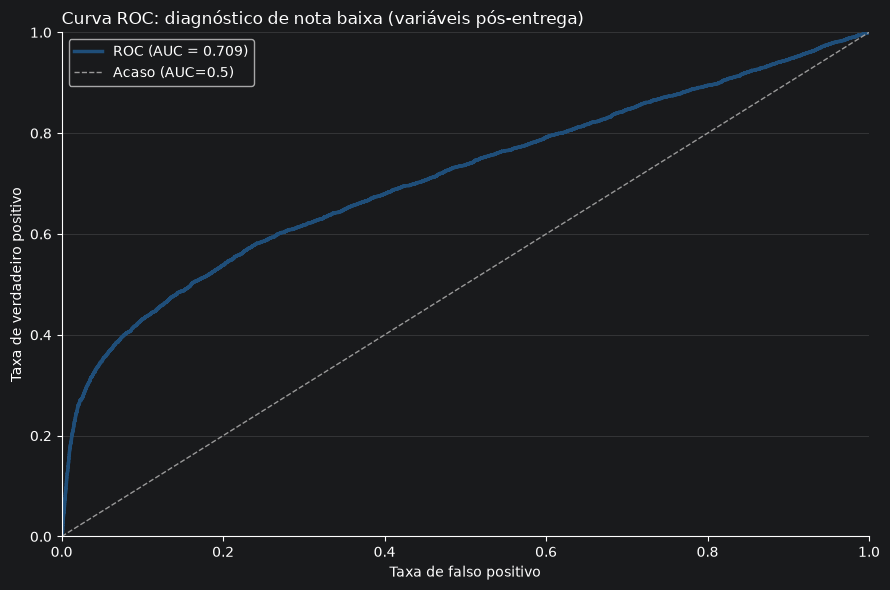

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))

fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
auc = roc_auc_score(y_test, y_pred_proba)

ax.plot(fpr, tpr, lw=2.5, color=COR, label=f'ROC (AUC = {auc:.3f})')
ax.plot([0, 1], [0, 1], lw=1, linestyle='--', color='#999', label='Acaso (AUC=0.5)')
ax.set_xlabel('Taxa de falso positivo')
ax.set_ylabel('Taxa de verdadeiro positivo')
ax.set_title('Curva ROC: diagnóstico de nota baixa (variáveis pós-entrega)', loc='left', fontsize=12)
ax.legend()
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
limpa(ax)

plt.tight_layout()
plt.savefig(FIG / '13_roc_nota_baixa.png', dpi=150)
plt.show()


## 8. Gráfico: Importância das features

Gera um gráfico de barras horizontais destacando visualmente os coeficientes positivos e negativos. Salva como figura.


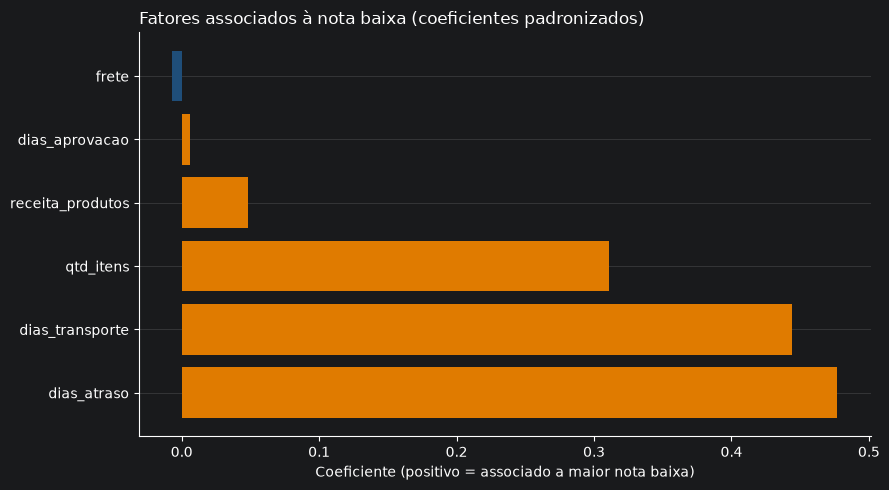

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))

cores = ['#e07b00' if x > 0 else '#1f4e79' for x in coef_df['Coeficiente']]
ax.barh(coef_df['Feature'], coef_df['Coeficiente'], color=cores)
ax.set_xlabel('Coeficiente (positivo = associado a maior nota baixa)')
ax.set_title('Fatores associados à nota baixa (coeficientes padronizados)', loc='left', fontsize=12)
limpa(ax)

plt.tight_layout()
plt.savefig(FIG / '14_features_nota_baixa.png', dpi=150)
plt.show()


## 9. Salvar tabelas e métricas


In [9]:
# Salva features
coef_df.to_csv(TAB / 'features_nota_baixa.csv', index=False)

# Calcula metricas
precisao = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

# Salva metricas
metricas_df = pd.DataFrame({
    'Metrica': ['Acurácia', 'ROC-AUC', 'Precisão (nota baixa)', 'Recall (nota baixa)'],
    'Valor': [round(acc, 3), round(auc, 3), round(precisao, 3), round(recall, 3)]
})
metricas_df.to_csv(TAB / 'metricas_modelo_nota_baixa.csv', index=False)

print(f'✅ Tabelas salvas em {TAB}')
print(f'\nMETRICAS DO MODELO:')
print(metricas_df.to_string(index=False))


✅ Tabelas salvas em ..\reports\tabelas

METRICAS DO MODELO:
              Metrica  Valor
             Acurácia  0.883
              ROC-AUC  0.709
Precisão (nota baixa)  0.716
  Recall (nota baixa)  0.147
